# Part A – Handling Missing Values
**Project:** Data Cleanser – Practical-2 (Data Preprocessing & Feature Engineering)  
**Domain:** Healthcare – patient health records → predicting *heart-disease risk*  
**Focus:** Missing-value analysis and 6 imputation techniques (Simple, Most-frequent, Missing-indicator + Random sample, KNN, MICE)

---

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# ---- paths (notebooks are run from the /Notebooks folder) ----
RAW   = "../Data/Raw/patient_health_records_raw.csv"
TRUTH = "../Data/External/ground_truth_clean_values.csv"   # clean values before corruption (evaluation only)
PROC  = "../Data/Processed/"
VIZ   = "../Visualization/"

SEED  = 42
NUM   = ["age", "bmi", "cholesterol", "glucose"]           # numeric columns that contain missing values
CAT   = ["gender", "region"]                               # categorical columns that contain missing values
OUTCOLS = ["bmi", "blood_pressure", "cholesterol", "glucose"]  # columns that contain outliers
print("Setup complete ✔")

Setup complete ✔

## Part A – Handling Missing Values
**Tasks covered:** (1) missing-value summary report, (2) six imputation techniques + comparison.

### A.1 Load the raw dataset

In [2]:
raw   = pd.read_csv(RAW)
truth = pd.read_csv(TRUTH)      # used ONLY to score how good each imputation is

print("Raw dataset shape   :", raw.shape)
print("Ground-truth shape  :", truth.shape)
print()
raw.info()

Raw dataset shape   : (500, 9)
Ground-truth shape  : (500, 9)

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      500 non-null    str    
 1   age             470 non-null    float64
 2   gender          475 non-null    str    
 3   region          475 non-null    str    
 4   bmi             460 non-null    float64
 5   blood_pressure  500 non-null    float64
 6   cholesterol     465 non-null    float64
 7   glucose         465 non-null    float64
 8   disease_risk    500 non-null    int64  
dtypes: float64(5), int64(1), str(3)
memory usage: 35.3 KB

In [3]:
raw.head(10)

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,PT0001,57.0,Male,East,29.1,125.4,184.5,109.6,0
1,PT0002,36.0,Male,West,26.3,121.3,190.2,80.5,0
2,PT0003,63.0,NaN,South,28.3,124.9,205.9,92.1,1
3,PT0004,66.0,Male,East,30.3,127.3,217.2,107.4,1
4,PT0005,23.0,Male,North,21.9,110.8,159.6,90.3,0
5,PT0006,32.0,Female,West,29.4,120.2,184.4,98.0,0
6,PT0007,54.0,Female,South,20.8,111.3,206.0,110.7,0
7,PT0008,47.0,Female,East,67.1,115.1,229.7,86.4,0
8,PT0009,52.0,Male,South,27.3,115.8,200.7,108.1,0
9,PT0010,NaN,NaN,South,23.4,118.4,197.3,72.1,0


In [4]:
raw.describe(include='all').T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,500,500,PT0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,470.0,NaN,NaN,NaN,51.995745,14.364876,18.0,42.0,52.0,61.0,90.0
gender,475,2,Male,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,475,4,North,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,460.0,NaN,NaN,NaN,26.179565,6.498803,8.7,22.7,26.0,28.9,70.7
blood_pressure,500.0,NaN,NaN,NaN,126.078,20.075568,94.4,117.4,123.45,130.225,265.4
cholesterol,465.0,NaN,NaN,NaN,201.323871,56.163147,50.0,174.9,197.5,220.7,618.3
glucose,465.0,NaN,NaN,NaN,99.551828,52.915534,65.0,83.5,92.1,100.1,499.0
disease_risk,500.0,NaN,NaN,NaN,0.394,0.489124,0.0,0.0,0.0,1.0,1.0


### A.2 Missing-value summary report (percentage per column) – *Task 1*

In [5]:
miss = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
}).sort_values("missing_%", ascending=False)
miss.to_csv(PROC + "missing_value_summary.csv")

total = raw.isna().sum().sum()
print(f"Total missing cells               : {total} ({total / raw.size * 100:.2f}% of all cells)")
print(f"Rows with >= 1 missing value      : {raw.isna().any(axis=1).sum()} ({raw.isna().any(axis=1).mean() * 100:.1f}% of rows)")
print(f"Rows that would be lost by dropna : {raw.isna().any(axis=1).sum()}  -> imputation is clearly preferable")
miss

Total missing cells               : 190 (4.22% of all cells)
Rows with >= 1 missing value      : 164 (32.8% of rows)
Rows that would be lost by dropna : 164  -> imputation is clearly preferable

,dtype,missing_count,missing_%
bmi,float64,40,8.0
glucose,float64,35,7.0
cholesterol,float64,35,7.0
age,float64,30,6.0
region,str,25,5.0
gender,str,25,5.0
patient_id,str,0,0.0
blood_pressure,float64,0,0.0
disease_risk,int64,0,0.0


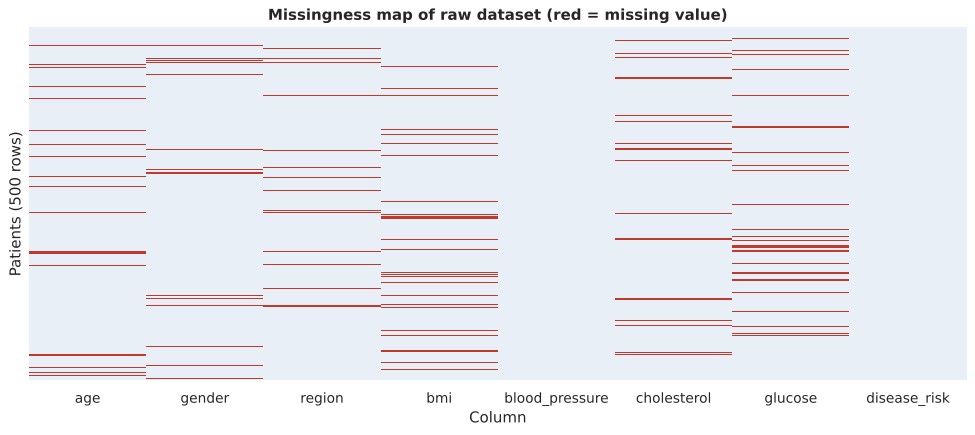

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(raw.drop(columns="patient_id").isna(), cbar=False, yticklabels=False,
            cmap=ListedColormap(["#e9eff7", "#c0392b"]), ax=ax)
ax.set_title("Missingness map of raw dataset (red = missing value)")
ax.set_xlabel("Column"); ax.set_ylabel("Patients (500 rows)")
plt.tight_layout(); plt.savefig(VIZ + "01_missing_values_map.png", dpi=150)
plt.show()

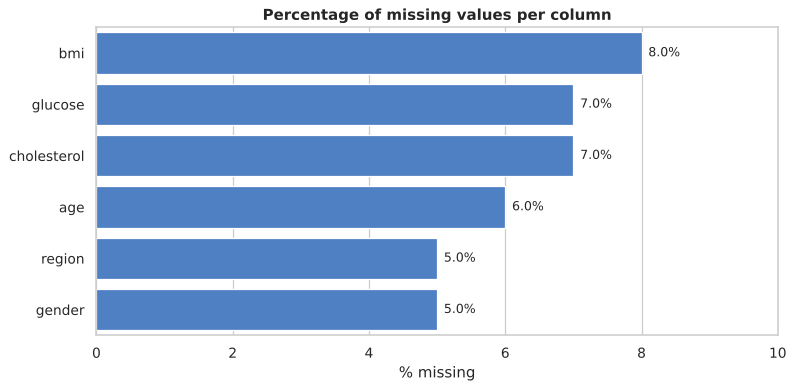

In [7]:
m = miss[miss["missing_%"] > 0].reset_index().rename(columns={"index": "column"})
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=m, x="missing_%", y="column", color="#3b7dd8", ax=ax)
for i, v in enumerate(m["missing_%"]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=10)
ax.set_title("Percentage of missing values per column"); ax.set_xlabel("% missing"); ax.set_ylabel("")
ax.set_xlim(0, m["missing_%"].max() + 2)
plt.tight_layout(); plt.savefig(VIZ + "02_missing_percentage_bar.png", dpi=150)
plt.show()

**Interpretation – missing values**
* **190 cells (4.22 %)** are missing, spread over **164 of the 500 patients (32.8 %)**. Simply dropping incomplete rows (`dropna`) would throw away a third of the data, so imputation is the right choice.
* `bmi` has the highest rate (**8 %**), followed by `cholesterol` and `glucose` (**7 % each**), `age` (**6 %**), and `gender` / `region` (**5 % each**). `patient_id`, `blood_pressure` and `disease_risk` are complete.
* The red dots in the map are scattered randomly with no block pattern, which suggests the data are *missing completely at random* – the situation in which the imputation techniques below are valid. No column exceeds 10 %, so none needs to be dropped.

### A.3 How will we score the imputations?
Because this dataset was *synthetically* generated, we kept a copy of the **true values before they were hidden** (`Data/External/ground_truth_clean_values.csv`).  
For every cell that was missing we can therefore measure the real imputation error:

* **Numeric columns** → RMSE and *normalised* RMSE (`RMSE / std of true column`, so columns with different units are comparable). Lower is better.
* **Categorical columns** → accuracy of the imputed category. Higher is better.

In [8]:
missing_mask = raw[NUM + CAT].isna()

def evaluate(imputed, name):
    """Score an imputed dataframe against the ground truth, on the originally-missing cells only."""
    row = {"method": name}
    for c in NUM:
        m = missing_mask[c]
        err = imputed.loc[m, c].astype(float) - truth.loc[m, c].astype(float)
        row[f"{c}_RMSE"] = np.sqrt((err ** 2).mean())
        row[f"{c}_NRMSE"] = row[f"{c}_RMSE"] / truth[c].std()
    for c in CAT:
        m = missing_mask[c]
        row[f"{c}_acc"] = (imputed.loc[m, c] == truth.loc[m, c]).mean()
    row["avg_NRMSE"] = np.mean([row[f"{c}_NRMSE"] for c in NUM])
    row["avg_cat_accuracy"] = np.mean([row[f"{c}_acc"] for c in CAT])
    row["bmi_imputed_std"] = imputed.loc[missing_mask["bmi"], "bmi"].astype(float).std()   # spread of imputed values
    return row

imputed = {}     # name -> fully imputed dataframe
print("Missing cells to be imputed:", int(missing_mask.sum().sum()))

Missing cells to be imputed: 190

### A.4 Technique 1 – Simple Imputer (numerical): mean / median

In [9]:
from sklearn.impute import SimpleImputer

# --- mean imputation ---
mean_df = raw.copy()
mean_df[NUM] = SimpleImputer(strategy="mean").fit_transform(raw[NUM])
# --- median imputation ---
median_df = raw.copy()
median_df[NUM] = SimpleImputer(strategy="median").fit_transform(raw[NUM])
for d in (mean_df, median_df):
    d["age"] = d["age"].round()                      # age is an integer

print("BMI – statistics before / after imputation")
cmp_bmi = pd.DataFrame({
    "raw (observed only)": raw["bmi"].describe(),
    "after MEAN impute": mean_df["bmi"].describe(),
    "after MEDIAN impute": median_df["bmi"].describe(),
}).round(2)
print("mean used  :", round(raw['bmi'].mean(), 2), "| median used :", round(raw['bmi'].median(), 2))
cmp_bmi

BMI – statistics before / after imputation
mean used  : 26.18 | median used : 26.0

,raw (observed only),after MEAN impute,after MEDIAN impute
count,460.00,500.00,500.00
mean,26.18,26.18,26.17
std,6.50,6.23,6.23
min,8.70,8.70,8.70
25%,22.70,23.00,23.00
50%,26.00,26.18,26.00
75%,28.90,28.52,28.52
max,70.70,70.70,70.70


**Interpretation – mean / median**
* The observed BMI mean (26.18) and median (26.00) are close, so both give almost the same result for BMI. The standard deviation shrinks from 6.50 to 6.23 and a spike appears at the centre of the distribution – the typical side-effect of constant imputation (variance is under-estimated and correlations are weakened).
* Because the data contain extreme values (BMI 8.7 – 70.7), the *mean* is pulled by outliers while the *median* is robust. The effect is largest for glucose (spikes up to 499 mg/dL): see the comparison in A.8, where median imputation has a clearly lower glucose error than mean imputation.

### A.5 Technique 2 – Simple Imputer (categorical): most-frequent value for `region`

In [10]:
cat_df = raw.copy()
cat_df[["region"]] = SimpleImputer(strategy="most_frequent").fit_transform(raw[["region"]])
print("Most frequent region used for imputation:", raw["region"].mode()[0])
pd.DataFrame({"before": raw["region"].value_counts(dropna=False),
              "after": cat_df["region"].value_counts(dropna=False)}).fillna(0).astype(int)

Most frequent region used for imputation: North

,before,after
region,,
East,97,97
North,155,180
South,144,144
West,79,79
NaN,25,0


### A.5b Technique 3 – Most Frequent Imputation for `gender`

In [11]:
gender_mode = raw["gender"].mode()[0]
gender_df = raw.copy()
gender_df["gender"] = gender_df["gender"].fillna(gender_mode)
print("Most common gender:", gender_mode)
pd.DataFrame({"before": raw["gender"].value_counts(dropna=False),
              "after": gender_df["gender"].value_counts(dropna=False)}).fillna(0).astype(int)

Most common gender: Male

,before,after
gender,,
Female,225,225
Male,250,275
NaN,25,0


**Interpretation – most-frequent imputation**
* `region`: North (the mode) grows from 155 to 180 rows; `gender`: Male grows from 250 to 275 rows. Mode imputation is simple and keeps the column valid, but it **inflates the majority class** and can bias the category proportions.
* With only 5 % missing the distortion is small. In this dataset gender and region carry almost no information about the other columns, so there is no better signal to exploit than the majority value.

### A.6 Technique 4 – Missing Indicator + Random Sample Imputation
Step 1: add a binary column `<col>_was_missing` (so the model can still learn from *the fact* that a value was missing).  
Step 2: fill each hole with a value drawn **at random from the observed values of the same column** – this keeps the original distribution (mean *and* spread).

In [12]:
rs_df = raw.copy()
rng = np.random.default_rng(SEED)
for c in NUM + CAT:
    mask = raw[c].isna()
    rs_df[f"{c}_was_missing"] = mask.astype(int)                       # missing indicator
    observed = raw[c].dropna().values
    rs_df.loc[mask, c] = rng.choice(observed, mask.sum(), replace=True)  # random sample imputation
rs_df["age"] = rs_df["age"].astype(float).round()

print("New indicator columns:", [c for c in rs_df.columns if c.endswith("_was_missing")])
rs_df[[c for c in rs_df.columns if c.endswith("_was_missing")]].sum().to_frame("rows flagged as missing")

New indicator columns: ['age_was_missing', 'bmi_was_missing', 'cholesterol_was_missing', 'glucose_was_missing', 'gender_was_missing', 'region_was_missing']

,rows flagged as missing
age_was_missing,30
bmi_was_missing,40
cholesterol_was_missing,35
glucose_was_missing,35
gender_was_missing,25
region_was_missing,25


### A.7 Technique 5 & 6 – KNN Imputer and MICE (multivariate)
Both techniques use the **other columns** to estimate a missing value:

* **KNN Imputer** – finds the *k = 5* most similar patients (distance computed on the standardised features) and averages their values (distance-weighted).
* **MICE** (`IterativeImputer`) – chained equations: each column with holes is regressed on all the others (Bayesian Ridge), and the loop is repeated until the estimates stabilise (15 rounds).

Categorical columns are encoded first (gender → 0/1, region → one-hot) so they can take part in the distance / regression, then decoded back to labels.

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer          # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge

REGIONS = ["East", "North", "South", "West"]
FEATS = ["age", "bmi", "blood_pressure", "cholesterol", "glucose"]

def encode(df):
    X = df[FEATS].astype(float).copy()
    X["gender_male"] = df["gender"].map({"Male": 1.0, "Female": 0.0})
    for r in REGIONS:
        X["region_" + r] = np.where(df["region"].isna(), np.nan, (df["region"] == r).astype(float))
    return X

def multivariate_impute(df, kind="knn"):
    X = encode(df)
    sc = StandardScaler()
    Xs = sc.fit_transform(X)                                         # NaNs are ignored when fitting
    if kind == "knn":
        imp = KNNImputer(n_neighbors=5, weights="distance")
    else:
        imp = IterativeImputer(estimator=BayesianRidge(), max_iter=15, random_state=SEED)
    Xi = pd.DataFrame(sc.inverse_transform(imp.fit_transform(Xs)), columns=X.columns, index=df.index)

    out = df.copy()
    for c in ["bmi", "blood_pressure", "cholesterol", "glucose", "age"]:
        out[c] = out[c].fillna(Xi[c])
    out["age"] = out["age"].round().clip(18, 90)
    out["gender"] = out["gender"].fillna(pd.Series(np.where(Xi["gender_male"] >= 0.5, "Male", "Female"), index=df.index))
    reg_cols = ["region_" + r for r in REGIONS]
    out["region"] = out["region"].fillna(pd.Series(np.array(REGIONS)[Xi[reg_cols].values.argmax(axis=1)], index=df.index))
    return out

knn_df  = multivariate_impute(raw, "knn")
mice_df = multivariate_impute(raw, "mice")
print("KNN  – missing left:", int(knn_df[NUM + CAT].isna().sum().sum()))
print("MICE – missing left:", int(mice_df[NUM + CAT].isna().sum().sum()))

KNN  – missing left: 0
MICE – missing left: 0

### A.8 Compare all imputation techniques – *Task 2 (comparison)*

In [14]:
# Combine the simple techniques into complete datasets (numeric strategy + categorical strategy)
mean_full = mean_df.copy();   mean_full[CAT] = SimpleImputer(strategy="most_frequent").fit_transform(raw[CAT])
median_full = median_df.copy(); median_full[CAT] = SimpleImputer(strategy="most_frequent").fit_transform(raw[CAT])

imputed = {
    "Mean + Most-frequent": mean_full,
    "Median + Most-frequent": median_full,
    "Missing-indicator + Random sample": rs_df[raw.columns.tolist()],
    "KNN (k=5)": knn_df,
    "MICE (Bayesian Ridge)": mice_df,
}
results = pd.DataFrame([evaluate(d, n) for n, d in imputed.items()]).set_index("method")
cols = ["age_NRMSE", "bmi_NRMSE", "cholesterol_NRMSE", "glucose_NRMSE", "avg_NRMSE",
        "gender_acc", "region_acc", "avg_cat_accuracy"]
results[cols].round(3)

,age_NRMSE,bmi_NRMSE,cholesterol_NRMSE,glucose_NRMSE,avg_NRMSE,gender_acc,region_acc,avg_cat_accuracy
method,,,,,,,,
Mean + Most-frequent,0.934,0.907,1.292,1.376,1.127,0.60,0.32,0.46
Median + Most-frequent,0.934,0.902,1.253,1.014,1.026,0.60,0.32,0.46
Missing-indicator + Random sample,1.533,1.619,2.344,1.533,1.757,0.40,0.20,0.30
KNN (k=5),0.808,1.014,1.591,2.799,1.553,0.56,0.08,0.32
MICE (Bayesian Ridge),0.994,0.853,1.124,1.305,1.069,0.64,0.32,0.48


In [15]:
rmse_tbl = results[[f"{c}_RMSE" for c in NUM]].round(2)
rmse_tbl["true std of BMI (missing cells)"] = round(truth.loc[missing_mask["bmi"], "bmi"].std(), 2)
rmse_tbl["std of imputed BMI values"] = results["bmi_imputed_std"].round(2)
rmse_tbl

,age_RMSE,bmi_RMSE,cholesterol_RMSE,glucose_RMSE,true std of BMI (missing cells),std of imputed BMI values
method,,,,,,
Mean + Most-frequent,13.36,3.78,41.90,16.32,3.79,0.00
Median + Most-frequent,13.36,3.76,40.62,12.03,3.79,0.00
Missing-indicator + Random sample,21.93,6.75,76.03,18.18,3.79,6.81
KNN (k=5),11.56,4.23,51.62,33.19,3.79,3.80
MICE (Bayesian Ridge),14.22,3.56,36.44,15.47,3.79,1.13


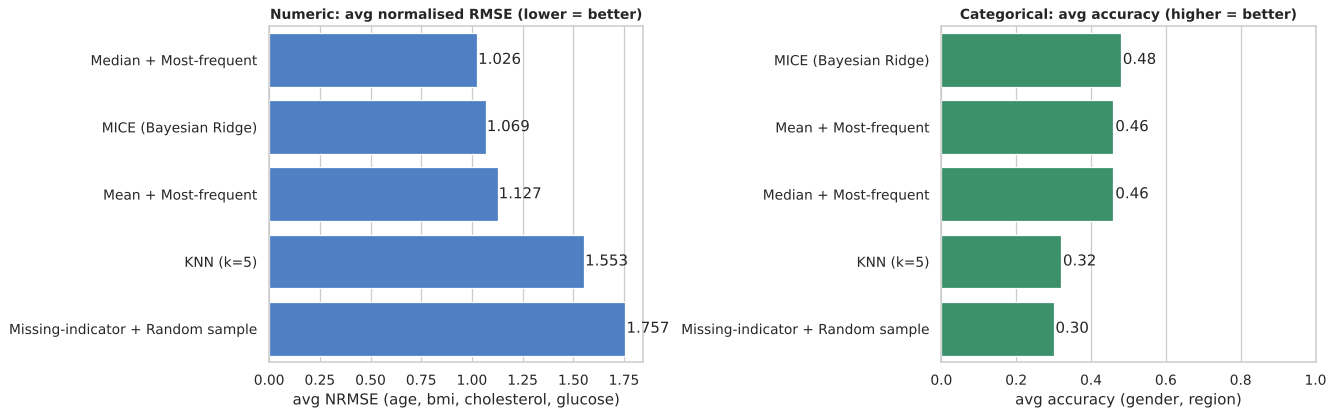

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
order = results.sort_values("avg_NRMSE").index
sns.barplot(x=results.loc[order, "avg_NRMSE"], y=order, color="#3b7dd8", ax=axes[0])
for i, v in enumerate(results.loc[order, "avg_NRMSE"]):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center")
axes[0].set_title("Numeric: avg normalised RMSE (lower = better)", fontsize=11)
axes[0].set_xlabel("avg NRMSE (age, bmi, cholesterol, glucose)"); axes[0].set_ylabel("")

order2 = results.sort_values("avg_cat_accuracy", ascending=False).index
sns.barplot(x=results.loc[order2, "avg_cat_accuracy"], y=order2, color="#2e9e6b", ax=axes[1])
for i, v in enumerate(results.loc[order2, "avg_cat_accuracy"]):
    axes[1].text(v + 0.005, i, f"{v:.2f}", va="center")
axes[1].set_title("Categorical: avg accuracy (higher = better)", fontsize=11)
axes[1].set_xlabel("avg accuracy (gender, region)"); axes[1].set_ylabel(""); axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.savefig(VIZ + "03_imputation_error_comparison.png", dpi=150)
plt.show()

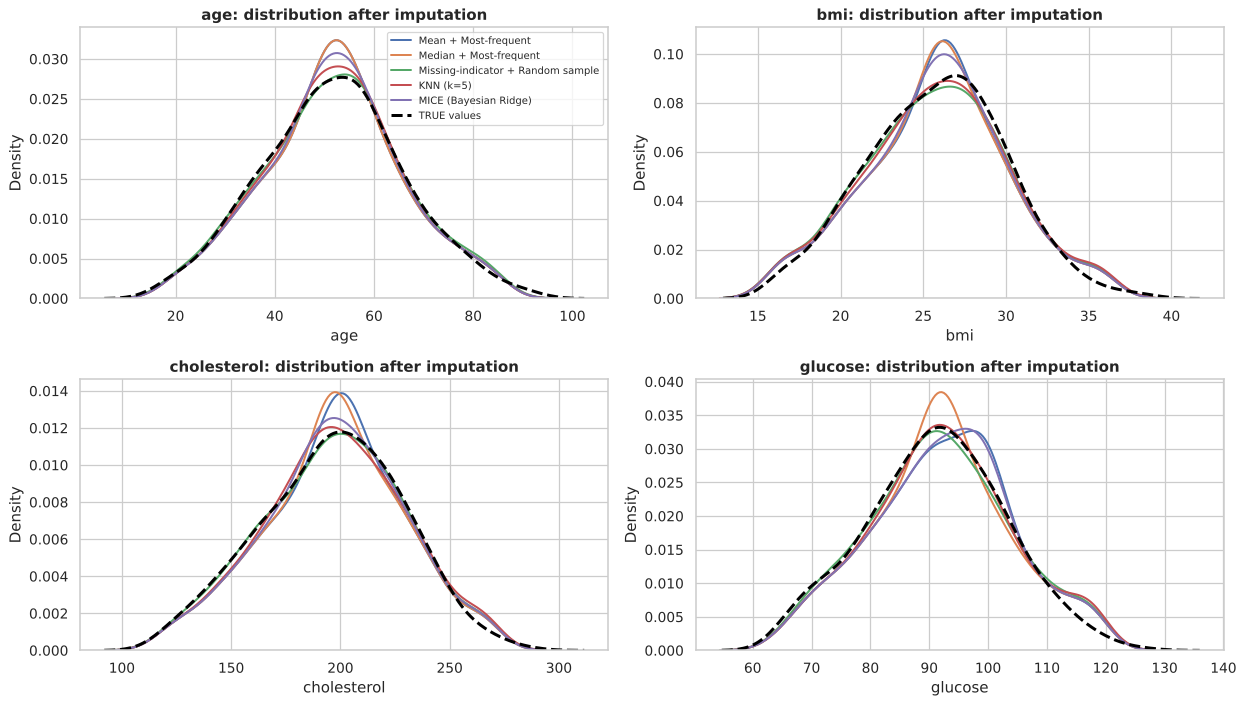

In [17]:
# How does each method change the DISTRIBUTION of the column? (trimmed to the 1st-99th percentile for readability)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, c in zip(axes.ravel(), NUM):
    lo, hi = truth[c].quantile([0.01, 0.99])
    for name, d in imputed.items():
        sns.kdeplot(d[c].astype(float).clip(lo, hi), ax=ax, label=name, lw=1.6)
    sns.kdeplot(truth[c].astype(float), ax=ax, label="TRUE values", color="black", lw=2.4, ls="--")
    ax.set_title(f"{c}: distribution after imputation"); ax.set_xlabel(c)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(VIZ + "04_imputation_distribution_comparison.png", dpi=150)
plt.show()

**Interpretation – comparison of the six techniques (scored against the hidden true values)**

| Technique | Strength | Weakness |
|---|---|---|
| Mean / Median + Most-frequent | fast, stable; median is robust to outliers | ignores relationships, shrinks variance |
| Missing-indicator + Random sample | keeps the original distribution and *flags* missingness for the model | adds noise; also copies outliers into the missing cells (imputed BMI std 6.8) |
| KNN (k = 5) | uses similar patients | distance is dominated by outlier-inflated features → large glucose error |
| MICE (Bayesian Ridge) | models each column from all others, preserves relationships | regression is also disturbed by extreme values |

* On the **raw** data (outliers still present) the **median** has the lowest average normalised RMSE (**1.026**), followed by MICE (1.069) and mean (1.127); KNN (1.553) and random sampling (1.757) are worst.
* Every score is close to or above 1.0, i.e. no technique beats "guess the average" by much. The reason is the extreme values in the *other* columns – they distort KNN distances, MICE regressions and the random sampling pool. **This ranking changes once outliers are neutralised** – see section C.1, where MICE becomes the clear winner.
* For the categorical columns no technique is reliably better than predicting the majority class (accuracy ≈ 0.3 for region, ≈ 0.6 for gender, computed on only 25 cells each, so differences of a few percent are noise).

### A.9 Select the best imputation and save all versions

In [18]:
best_num = results["avg_NRMSE"].idxmin()
best_cat = results["avg_cat_accuracy"].idxmax()
print("Best numeric imputation     :", best_num, f"(avg NRMSE = {results.loc[best_num, 'avg_NRMSE']:.3f})")
print("Best categorical imputation :", best_cat, f"(avg accuracy = {results.loc[best_cat, 'avg_cat_accuracy']:.3f})")

best = imputed[best_num].copy()
best[CAT] = imputed[best_cat][CAT]

# save every version + the comparison table
files = {"Mean + Most-frequent": "imputed_mean_mode.csv", "Median + Most-frequent": "imputed_median_mode.csv",
         "Missing-indicator + Random sample": "imputed_random_sample_with_indicators.csv",
         "KNN (k=5)": "imputed_knn.csv", "MICE (Bayesian Ridge)": "imputed_mice.csv"}
for name, fn in files.items():
    d = rs_df if name.startswith("Missing") else imputed[name]
    d.to_csv(PROC + fn, index=False)
best.to_csv(PROC + "imputed_best.csv", index=False)
results.round(4).to_csv(PROC + "imputation_comparison.csv")
print("Remaining missing values in best dataset:", int(best.isna().sum().sum()))
print("Saved ->", PROC)

Best numeric imputation     : Median + Most-frequent (avg NRMSE = 1.026)
Best categorical imputation : MICE (Bayesian Ridge) (avg accuracy = 0.480)
Remaining missing values in best dataset: 0
Saved -> ../Data/Processed/